In [1]:
import numpy as np
import matplotlib.pyplot as plt

import fig_settings as fs

fs.set_colors()
fs.set_fonts()

In [2]:
# Parameters
k = 18.0
gamma = 0.1
omega = 0.1
beta1 = 0.01
beta2 = 0.04

In [3]:
# Compute block-effective infectivities
b1 = (1 - omega) * beta1 + omega * beta2
b2 = (1 - omega) * beta2 + omega * beta1

# Parameter ranges
delta = np.linspace(-1, 1, 201)
epsilon = np.linspace(0, 1, 201)

D, E = np.meshgrid(delta, epsilon)

# R0 computation
trace = (b1 + b2) + D * (b1 - b2) # up to prefactor

discriminant = (
    ((b1 - b2) + D * (b1 + b2))**2
    + ((1 - E) / (1 + E))**2 * ((b1 + b2)**2 - (b1 - b2)**2)
)

R0 = (k * (1 + E) / (4 * gamma)) * (trace + np.sqrt(discriminant))

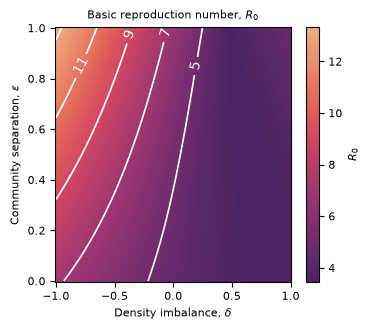

In [5]:
PANEL_W = 3   # width  of panel in inches
PANEL_H = 3    # height of panel

LMARGIN   = 0.4   # left margin
RMARGIN   = 0.4   # right margin
TMARGIN   = 0.2   # top margin
BMARGIN   = 0.2   # bottom margin

fig_w = LMARGIN + PANEL_W + RMARGIN
fig_h = TMARGIN + PANEL_H + BMARGIN

fig, ax = plt.subplots(figsize=(fig_w, fig_h))

pcm = ax.pcolormesh(
    D,
    E,
    R0,
    cmap=fs.complexity_cmap,
    edgecolor='face'
)
# Contours
levels = np.arange(
    np.floor(R0.min()),
    np.ceil(R0.max()) + 0.5,
    2
)

cs = ax.contour(
    D,
    E,
    R0,
    levels=levels,
    colors="white",
    linewidths=1.2
)

ax.clabel(cs, inline=True, fontsize=10) #, fmt="%.1f")

cbar = plt.colorbar(pcm, ax=ax)
cbar.set_label(r"$R_0$")

ax.set_xlabel(r"Density imbalance, $\delta$")
ax.set_ylabel(r"Community separation, $\varepsilon$")
ax.set_title(r"Basic reproduction number, $R_0$")

plt.tight_layout()

plt.savefig('../figs/figS3.svg', bbox_inches='tight')
plt.savefig('../figs/figS3.pdf', bbox_inches='tight')
plt.show()